In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.plotting import plot_decision_regions
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_circles

import warnings
warnings.filterwarnings('ignore')

In [4]:
np.random.seed(42)
X,y=make_circles(n_samples=500, factor=0.1, noise=0.35, random_state=42)

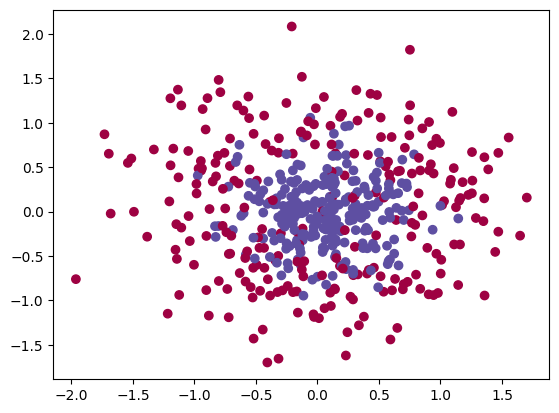

In [5]:
plt.scatter(X[:,0], X[:,1], c=y, cmap=plt.cm.Spectral)
plt.show()

In [6]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import cross_val_score

adaboost_clf = AdaBoostClassifier()
np.mean(cross_val_score(
    adaboost_clf,
    X,
    y,
    cv=10,
    scoring='accuracy'
))

np.float64(0.812)

In [7]:
adaboost_clf.fit(X,y)

AdaBoostClassifier()

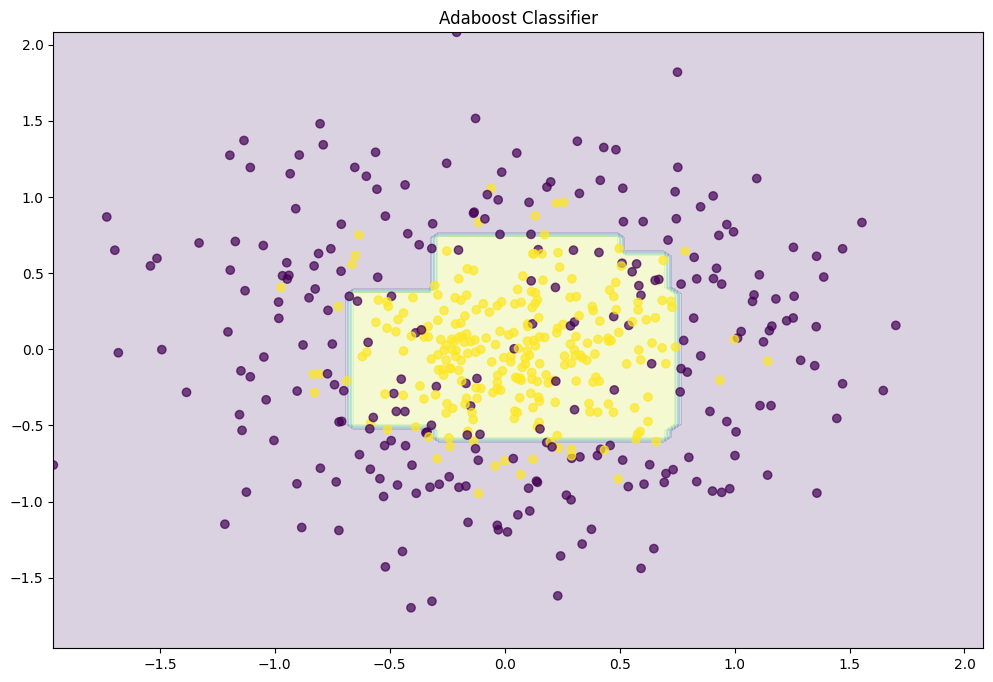

In [8]:
def plot_decision_boundary(clf):
    plt.figure(figsize=(12, 8))
    x_range = np.linspace(X.min(), X.max(), 100)
    xx1, xx2 = np.meshgrid(x_range, x_range)
    y_hat = clf.predict(np.c_[xx1.ravel(), xx2.ravel()])
    y_hat = y_hat.reshape(xx1.shape)
    plt.contourf(xx1, xx2, y_hat, alpha=0.2)
    plt.scatter(X[:,0], X[:,1], c=y, cmap='viridis', alpha=.7)
    plt.title("Adaboost Classifier")
    plt.show()

plot_decision_boundary(adaboost_clf)

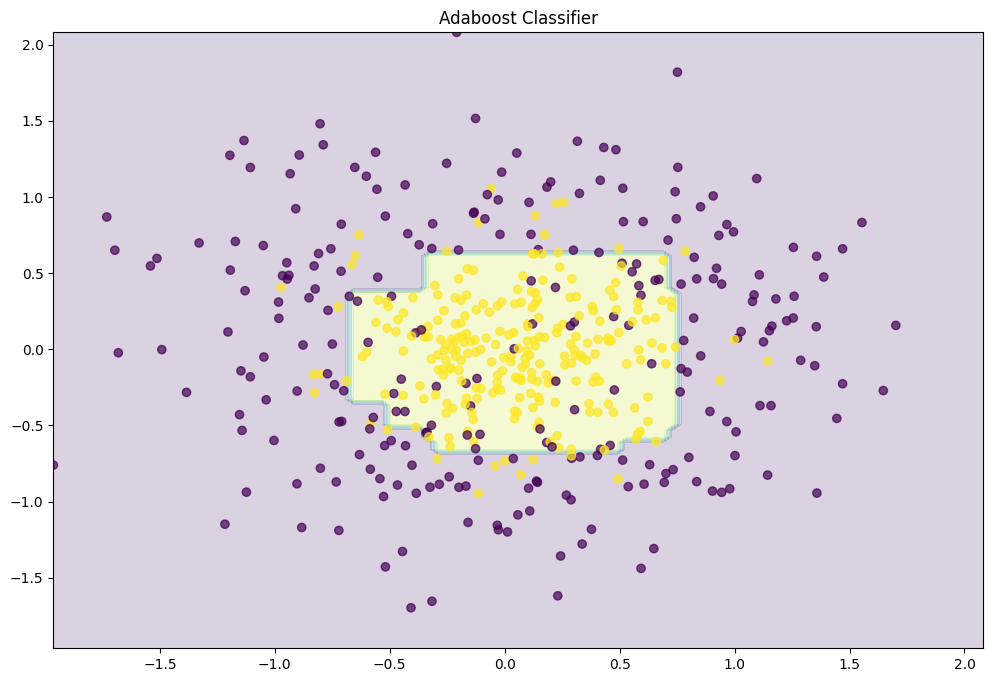

In [9]:
adaboost_clf2 = AdaBoostClassifier(
    n_estimators=200,
    learning_rate=0.5
)
adaboost_clf2.fit(X,y)
plot_decision_boundary(adaboost_clf2)

# GridSearchCV

In [10]:
from sklearn.model_selection import GridSearchCV

grid_param = {
    'n_estimators': [100, 200, 300, 400, 500],
    'learning_rate': [0.1, 0.5, 1],
    'algorithm': ['SAMME', 'SAMME.R']
}
grid_search = GridSearchCV(
    estimator=AdaBoostClassifier(),
    param_grid=grid_param,
    cv=10,
    scoring='accuracy'
)
grid_search.fit(X,y)

GridSearchCV(cv=10, estimator=AdaBoostClassifier(),
             param_grid={'algorithm': ['SAMME', 'SAMME.R'],
                         'learning_rate': [0.1, 0.5, 1],
                         'n_estimators': [100, 200, 300, 400, 500]},
             scoring='accuracy')

In [11]:
# Best params
grid_search.best_params_

{'algorithm': 'SAMME', 'learning_rate': 0.1, 'n_estimators': 500}

In [12]:
# Best score
grid_search.best_score_

np.float64(0.8320000000000001)

In [13]:
# Best model
grid_search.best_estimator_

AdaBoostClassifier(algorithm='SAMME', learning_rate=0.1, n_estimators=500)